In [1]:
import sys
import os
import importlib.util
from pathlib import Path

APP_DIR = "D:/generate_3/Wing_generation/exp/Transformer_exp25"
# 从指定路径导入 WingAutoregressiveTransformer（避免与当前目录同名文件冲突）
# target_file = APP_DIR + '/code/WingAutoregressiveTransformer.py'

# # 创建模块规范
# spec = importlib.util.spec_from_file_location("WingAutoregressiveTransformer_exp", target_file)
# WingAutoregressiveTransformer = importlib.util.module_from_spec(spec)
# spec.loader.exec_module(WingAutoregressiveTransformer)

# # 从导入的模块中获取类
# WingArTransformer = WingAutoregressiveTransformer.WingArTransformer
from WingAutoregressiveTransformer import WingArTransformer

# 其他导入
import torch
import numpy as np
from WingScriptGenerator import param_to_ggs_wing_dict, calculate_wing_mac
import math
from wingVAE import WingVAE
import os
from math import radians, cos, sin, asin, sqrt, atan2, degrees
from pathlib import Path

In [2]:
from general_generation_system import AircraftScriptGenerator
generator = AircraftScriptGenerator()

In [3]:
VAE_model = WingVAE(
        input_dim=46, 
        latent_dim=32, 
        hidden_dim=256, 
        condition_dim=3,
        switch_epoch=200, 
        kl_coeff=0.005, 
        phys_coeff=1.5
    )

#加载模型权重
model_path = "D:/generate_3/Wing_generation/exp/Encoder_exp21"
checkpoint = torch.load(os.path.join(model_path, "last.ckpt"), map_location=torch.device('cpu'))
VAE_model.load_state_dict(checkpoint['state_dict'])
VAE_model.eval()

C:\Users\WednZ\AppData\Local\Temp\ipykernel_62180\3614468434.py:13: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(os.path.join(model_path, "last.ckpt

WingVAE(
  (encoder_backbone): Sequential(
    (0): Linear(in_features=46, out_features=256, bias=True)
    (1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=256, bias=True)
    (4): ReLU()
  )
  (fc_mu): Linear(in_features=256, out_features=32, bias=True)
  (fc_var): Linear(in_features=256, out_features=32, bias=True)
  (decoder_geometry): Sequential(
    (0): Linear(in_features=32, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=46, bias=True)
  )
  (decoder_physics): Sequential(
    (0): Linear(in_features=35, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=3, bias=True)
  )
)

对WingArTransformer进行最小case测试

In [4]:
AR_model = WingArTransformer(
    pretrained_vae=VAE_model,
    latent_dim=32,
    embed_dim=128)

In [5]:
#加载模型权重
# model_path = "D:/generate_3/Wing_generation/exp/Transformer_exp06"
AR_model_path = os.path.join(APP_DIR, "last.ckpt")
print(AR_model_path)
checkpoint = torch.load(AR_model_path, map_location=torch.device('cpu'))
AR_model.load_state_dict(checkpoint['state_dict'], strict=False)
AR_model.eval()

D:/generate_3/Wing_generation/exp/Transformer_exp25\last.ckpt


C:\Users\WednZ\AppData\Local\Temp\ipykernel_62180\1586307683.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(AR_model_path, map_location=torch.de

WingArTransformer(
  (vae): WingVAE(
    (encoder_backbone): Sequential(
      (0): Linear(in_features=46, out_features=256, bias=True)
      (1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
      (2): ReLU()
      (3): Linear(in_features=256, out_features=256, bias=True)
      (4): ReLU()
    )
    (fc_mu): Linear(in_features=256, out_features=32, bias=True)
    (fc_var): Linear(in_features=256, out_features=32, bias=True)
    (decoder_geometry): Sequential(
      (0): Linear(in_features=32, out_features=256, bias=True)
      (1): ReLU()
      (2): Linear(in_features=256, out_features=256, bias=True)
      (3): ReLU()
      (4): Linear(in_features=256, out_features=46, bias=True)
    )
    (decoder_physics): Sequential(
      (0): Linear(in_features=35, out_features=256, bias=True)
      (1): ReLU()
      (2): Linear(in_features=256, out_features=256, bias=True)
      (3): ReLU()
      (4): Linear(in_features=256, out_features=3, bias=True)
    )
  )
  (cond_embeddings): Mod

In [42]:
# 示例1：完整工况（含 cm）
conditions_full = torch.tensor([[
    [ 0.0220,  0.9998,  0.8200,  0.2347,  0.0146, -0.2500], # sin(alpha), cos(alpha), Ma, cl, cd, cm
    [ 0.0245,  0.9997,  0.8200,  0.2449,  0.0152, -0.2603],
    [ 0.0361,  0.9993,  0.8200,  0.2909,  0.0186, -0.3066],
    [ 0.0392,  0.9992,  0.8200,  0.3031,  0.0197, -0.3189],
    [ 0.0500,  0.9988,  0.8200,  0.3427,  0.0237, -0.3580],
    [ 0.0474,  0.9989,  0.8500,  0.3340,  0.0281, -0.3536],
    [ 0.0211,  0.9998,  0.8500,  0.2420,  0.0186, -0.2628],
    [ 0.0249,  0.9997,  0.8500,  0.2573,  0.0199, -0.2784],
    [ 0.0324,  0.9995,  0.8500,  0.2878,  0.0227, -0.3093],
    [ 0.0432,  0.9991,  0.8500,  0.3209,  0.0264, -0.3411]
]])

# 示例2：缺失 cm
conditions_part = torch.tensor([[
    [ 0.0220,  0.9998,  0.8200,  0.2347,  0.0146, -0.2500],
    [ 0.0245,  0.9997,  float('nan'),  0.2449,  0.0152, -0.2603],
    [ 0.0361,  0.9993,  0.8200,  0.2909,  0.0186, -0.3066],
    [ 0.0392,  0.9992,  0.8200,  0.3031,  0.0197, -0.3189],
    [ 0.0500,  0.9988,  0.8200,  float('nan'),  0.0237, -0.3580],
    [ 0.0474,  0.9989,  0.8500,  0.3340,  0.0281, -0.3536],
    [ 0.0211,  0.9998,  0.8500,  0.2420,  float('nan'), -0.2628],
    [ 0.0249,  0.9997,  0.8500,  0.2573,  0.0199, -0.2784],
    [ 0.0324,  float('nan'),  0.8500,  0.2878,  float('nan'), float('nan')],
    [ 0.0432,  0.9991,  0.8500,  0.3209,  0.0264, -0.3411]
]])

empty_ac = torch.tensor([[[float('nan')]* 5]] , dtype=torch.float32)

cond_dict = {
    'ar_target': torch.tensor([22], dtype=torch.float32),
    'ac': conditions_full #根据缺失情况填写不同的条件
    }



In [43]:
assigned_airfoil = [ 0.21831445,  0.10735435,  0.33254817, -0.02141487,  0.47346475,
       -0.02094183,  0.44769637,  0.14321052,  0.13721545,  0.03332585,
       -0.21710493, -0.11109526, -0.3291897 ,  0.02345906, -0.48635854,
        0.03187712, -0.44178299, -0.14960563, -0.12526484, -0.03484113]

In [44]:
generatedWing, generated_diherals, scale_factors, C_ref, generated_eos, current_span, current_area = AR_model.generate_with_constraints(cond_dict, assigned_airfoil=None)

使用默认值的 AR_target 和 C_ref。设计指标AR_target: tensor([22.]), span: tensor([66.]), area: tensor([198.])
all samples are done


接下来把生成的机翼部件序列恢复成原始面貌

1. 先反归一化为部件表述
2. 整合成Dict，直接调用函数转为GGS参数
3. 调用GGS生成脚本
4. 还要对比一下衔接处的差异，后续要把这个差异作为损失项进行训练

In [45]:
current_span, current_area, generated_diherals

(tensor([[32.6585]]),
 tensor([[90.6225]]),
 tensor([[-0.1078, -0.5055, -0.9375, -4.2501]]))

In [46]:
# generatedWWingArray = generatedWWing[:, 1:, :].cpu().numpy() #去掉翼型引导段
generatedWingArray = generatedWing.cpu().numpy() 
generated_diherals = generated_diherals.cpu().numpy()
scale_factors = scale_factors.cpu().numpy()
c_ref = C_ref.item()
# 不需要反归一化，类内已经内置

In [47]:
init_sec_params = {
    "upper_cst_params_root" : generatedWingArray[0, 0, 0:10],
    "lower_cst_params_root" : generatedWingArray[0, 0, 10:20],
    "upper_cst_params_tip" : generatedWingArray[0, 0, 20:30],
    "lower_cst_params_tip" : generatedWingArray[0, 0, 30:40],
    "span" : generatedWingArray[0, 0, 41] * c_ref * scale_factors[0, 0].item(),
    "chord_root" : c_ref * scale_factors[0, 0].item(),
    "chord_tip" : generatedWingArray[0, 0, 40] * c_ref * scale_factors[0, 0].item(),
    "sweep" : degrees(atan2(generatedWingArray[0, 0, 42], generatedWingArray[0, 0, 43])),
    "washout" : degrees(atan2(generatedWingArray[0, 0, 44], generatedWingArray[0, 0, 45])),
    "dihedral" : generated_diherals[0, 0]  # 添加上反角信息
}

mid_sec_params = []
for i in range(1, generatedWingArray.shape[1]):
    mid_sec_params.append({
        "upper_cst_params_root" : generatedWingArray[0, i, 0:10],
        "lower_cst_params_root" : generatedWingArray[0, i, 10:20],
        "upper_cst_params_tip" : generatedWingArray[0, i, 20:30],
        "lower_cst_params_tip" : generatedWingArray[0, i, 30:40],
        "span" : generatedWingArray[0, i, 41] * c_ref * scale_factors[0, i].item(),
        "chord_root" : c_ref * scale_factors[0, i].item(),
        "chord_tip" : generatedWingArray[0, i, 40] * c_ref * scale_factors[0, i].item(),
        "sweep" : degrees(atan2(generatedWingArray[0, i, 42], generatedWingArray[0, i, 43])),
        "washout" : degrees(atan2(generatedWingArray[0, i, 44], generatedWingArray[0, i, 45])),
        "dihedral" : generated_diherals[0, i]  # 添加上反角信息
    })

In [48]:
param_dict = {
    "init": init_sec_params,
    "mid": mid_sec_params
}
ggs_wing_dict = param_to_ggs_wing_dict(param_dict, angle_of_incidence=0)
ggs_wing_dict["global"] = { "planar": 0 }

In [49]:
# SCRIPT_DIR = Path("D:/generate_3/Wing_generation/src")
# generator.generate_script(
#     script_file_path = SCRIPT_DIR / f'script.vspscript',
#     global_params = None,
#     fuselage = None,
#     wings = [ggs_wing_dict]
#     )

In [50]:
# 生成对应的stl文件
SCRIPT_DIR = Path("D:/generate_3/Wing_generation/src")
generator.generate_script(
    script_file_path = SCRIPT_DIR / f'script.vspscript',
    global_params = None,
    fuselage = None,
    wings = [ggs_wing_dict],
    save_stl = True,
    save_file_path = str(SCRIPT_DIR).replace("\\", "/"),
    id_str = f'test'
    )

In [51]:
import subprocess
VSP_PATH = "D:\\SW\\OpenVSP-3.45.4-win64\\vsp.exe"
# 调用OpenVSP得到几何
cmd = [
    VSP_PATH,
    "-script",
    SCRIPT_DIR / f'script.vspscript'
]

# 执行命令
result = subprocess.run(
    cmd,
    capture_output=True,  # 捕获 stdout 和 stderr
    text=True,            # 返回字符串而非字节
    cwd="."               # 设置工作目录（可选，确保 .\SZ300_new.vspscript 能找到）
)

# 检查结果
if result.returncode != 0:
    print("Command failed!")
    print("error:", result.stderr)

In [52]:
geo_char = calculate_wing_mac(ggs_wing_dict)

In [53]:
geo_char

{'area': 90.50677497352274,
 'mac_length': 2.8861712871091685,
 'x_lemac': 5.343712215464358,
 'span': 32.603858294312175}

In [54]:
print(geo_char['span']**2*2/geo_char['area'])

23.49021000884336


🚀 加载AeroTransformer模型...
loading model...
loading single model ATsurf_L_v1...
📂 加载STL文件: D:\generate_3\Wing_generation\src\test.stl
⏳ 开始进行展向站位切片插值（257x129节点阵列）...
✅ 节点网格(Node)生成成功。最终矩阵形状: (257, 129, 3)
🚀 中心点网格(Cell)计算完毕！最终矩阵形状: (256, 128, 3)


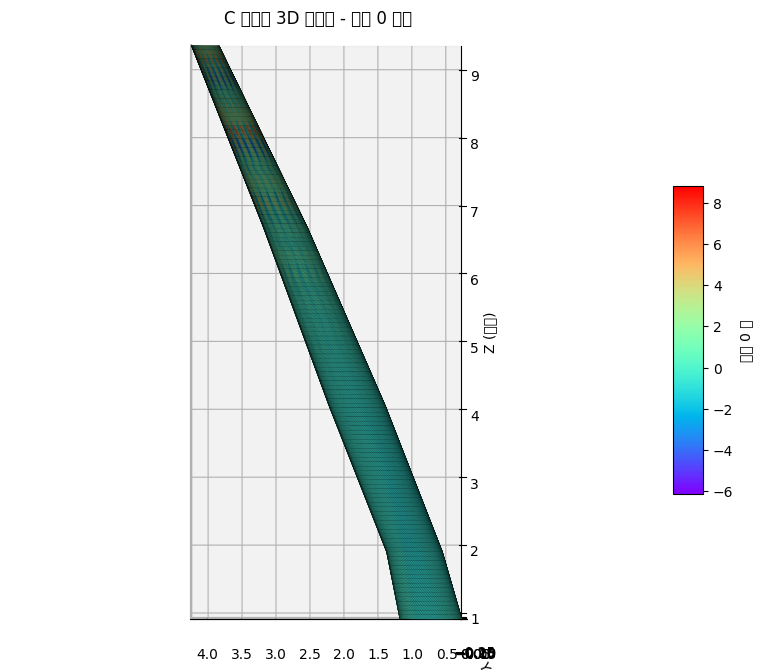

In [55]:
from AeroTransformerPredict import AeroTransformer

cnd = np.array([[9.69, 0.88]])
aero_transformer_predict = AeroTransformer()
root_chord = C_ref * scale_factors[0, 0].item()
area = geo_char['area']
mac = geo_char['mac_length']
aero_transformer_predict.build_grid(file_path=SCRIPT_DIR / f'test.stl', root_chord=root_chord, area=area, mac=mac)
flowfield, origeom, geom = aero_transformer_predict.predict_flow_field(aoa=cnd[0, 0], mach=cnd[0, 1])
aero_transformer_predict.plot_flow_field(flowfield, origeom, channel='pressure')

In [56]:
inp = torch.tensor(origeom,dtype=torch.float32).unsqueeze(0)
outputs = torch.tensor(flowfield,dtype=torch.float32)
print(inp.shape, outputs.shape)

torch.Size([1, 3, 129, 257]) torch.Size([1, 3, 128, 256])


In [57]:
end2end_coeffs = aero_transformer_predict.predict_coeffs(aoa_array=cnd[:, 0], mach_array=cnd[:, 1])
print(end2end_coeffs)

[[0.34445515 0.04538917 0.6940188 ]]


In [58]:
from AeroTransformerPredict import integrate_wing_aerodynamics

In [59]:
coeffs = integrate_wing_aerodynamics(inp, outputs, s_ref=geo_char['area']/(root_chord**2), c_ref=geo_char['mac_length']/root_chord, x_ref=0, y_ref=0, alpha_deg=cnd[0, 0], include_friction=False)
coeffs

{'CL': 0.28289029002189636,
 'CD': 0.03564998880028725,
 'CM': 0.4880775809288025}